In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import build_model, halofit
from astropy.stats import sigma_clip
from mytools.data import read_h5, vitems

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

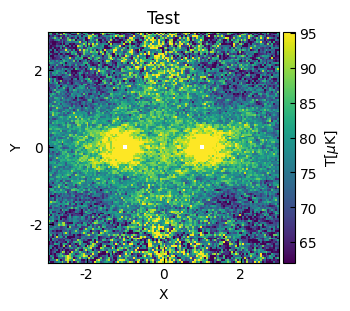

In [5]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [6]:
coord = get_coord()

name = 'nfw'
bg_name = 'poly'
# bg_name = 'const'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'ellipticity_0': (0, 0.5),
    'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

init_bg = {
    "degree": 2
}

model = build_model(name, bg_name, init_bg=init_bg, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Polynomial2D(2, c0_0=0., c1_0=0., c2_0=0., c0_1=0., c0_2=0., c1_1=0., x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(2, c0_0=0., c1_0=0., c2_0=0., c0_1=0., c0_2=0., c1_1=0., x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... c2_0_3 c0_1_3 c0_2_3 c1_1_3
    ----------- -------- -------- ----- ... ------ ------ ------ ------
           50.0     -1.0      0.0   0.5 ...    0.0    0.0    0.0    0.0


In [7]:
# pixcount weight
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
vitems(weight_path)

Item: crafts_122k
Type: Group
Attributes (0):
 None
Item: crafts_122k/npair
Type: Dataset
Shape: ()
Dtype: int64
Attributes (0):
 None
Item: crafts_122k/pixcount
Type: Dataset
Shape: (21, 120, 120)
Dtype: int64
Attributes (0):
 None
Item: crafts_122k/weight
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_120k
Type: Group
Attributes (0):
 None
Item: tng_120k/npair
Type: Dataset
Shape: ()
Dtype: int64
Attributes (0):
 None
Item: tng_120k/pixcount
Type: Dataset
Shape: (21, 120, 120)
Dtype: int64
Attributes (0):
 None
Item: tng_120k/weight
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None


<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

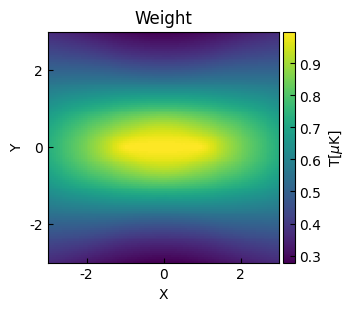

In [8]:
# weights = read_h5(weight_path, 'tng_120k/weight')
weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(weights, title='Weight', q=0.1)

# without mask

In [9]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True, weights=weights)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.25043442, x_mean=-1., y_mean=0., r_s=22.17101961, ellipticity=0., theta=3.346813)>

    [1]: <NFW2D(amplitude=0.25043442, x_mean=1., y_mean=0., r_s=22.62171663, ellipticity=0., theta=9.30020625)>

    [2]: <Polynomial2D(2, c0_0=32.42609974, c1_0=11.64386995, c2_0=7.15946739, c0_1=4.22396278, c0_2=4.04645056, c1_1=21.06464103, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(2, c0_0=32.5512917, c1_0=-24.03252114, c2_0=-10.87561255, c0_1=-18.37377748, c0_2=-10.93500961, c1_1=-20.67011304, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
        amplitude_0     x_mean_0 ...        c0_2_3              c1_1_3      
    ------------------- -------- ... ------------------- -------------------
    0.25043441695803537     -1.0 ... -10.935009610132555 -20.670113035294744

Goodness of fit:
Chi-squared: 987134.684

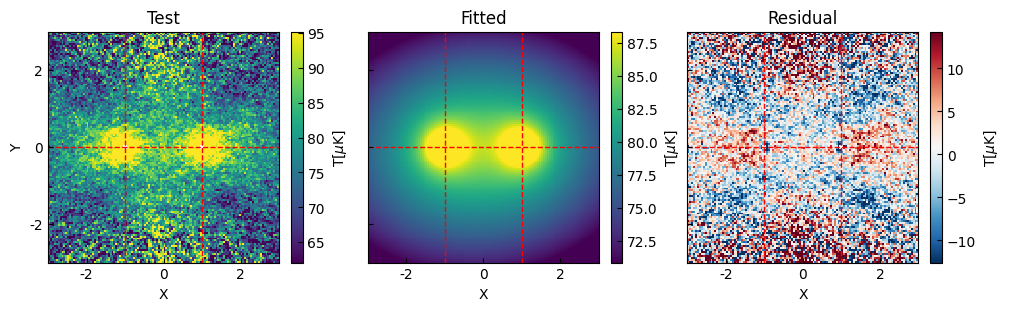

In [10]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

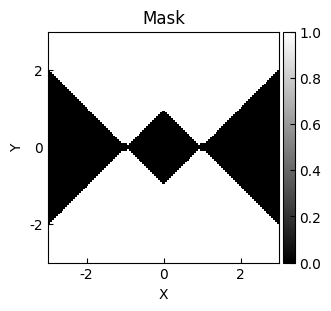

In [11]:
# mask_sector = get_mask_sector(coord=coord)
mask_sector = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask_sector = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask_sector, title='Mask', cmap='gray', cbar_label='')

In [12]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask_sector, print_model=True, weights=weights[mask_sector])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.05780235, x_mean=-1., y_mean=0., r_s=109.97668711, ellipticity=0.05164668, theta=48.90606342)>

    [1]: <NFW2D(amplitude=0.05780235, x_mean=1., y_mean=0., r_s=113.81596448, ellipticity=0.05164668, theta=-2.85197278)>

    [2]: <Polynomial2D(2, c0_0=33.34681744, c1_0=10.93299507, c2_0=-5.24093985, c0_1=-0.08374197, c0_2=0.87104863, c1_1=0.14709902, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(2, c0_0=33.34678241, c1_0=-11.29822166, c2_0=-4.9971876, c0_1=-0.07680353, c0_2=0.8713825, c1_1=0.20104721, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
        amplitude_0     x_mean_0 y_mean_0 ...       c0_2_3              c1_1_3      
    ------------------- -------- -------- ... ------------------ -------------------
    0.05780235408093732     -1.0      0.0 ... 0.8713825032662471 0.20104721326131367



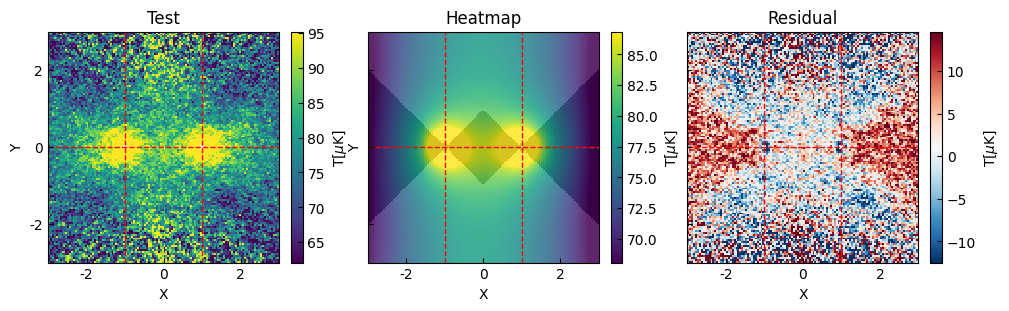

In [13]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

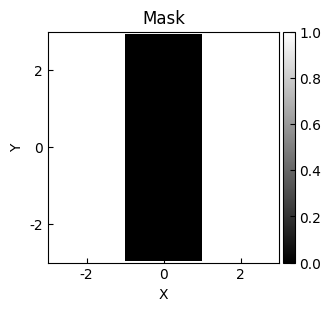

In [14]:
# mask_sq = ~get_mask_square(coord=coord)
mask_sq = ~get_mask_square(coord=coord, xlim=[-1, 1], ylim=[-3, 3])

plot_heatmap(mask_sq, title='Mask', cmap='gray', cbar_label='')

In [15]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask_sq, print_model=True, weights=weights[mask_sq])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.13741343, x_mean=-1., y_mean=0., r_s=59.68683485, ellipticity=0.37451433, theta=0.06843299)>

    [1]: <NFW2D(amplitude=0.13741343, x_mean=1., y_mean=0., r_s=61.07872303, ellipticity=0.37451433, theta=-0.00387709)>

    [2]: <Polynomial2D(2, c0_0=1.14205576, c1_0=-4.05536799, c2_0=51.03244778, c0_1=-192.92830186, c0_2=47.82142969, c1_1=22.81487563, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(2, c0_0=52.55663158, c1_0=-66.18826357, c2_0=-53.80644729, c0_1=177.63129947, c0_2=-54.49992932, c1_1=-22.51318518, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
        amplitude_0     x_mean_0 ...        c0_2_3              c1_1_3      
    ------------------- -------- ... ------------------- -------------------
    0.13741342983912588     -1.0 ... -54.499929321113115 -22.513185184444122

Goodness of fit:

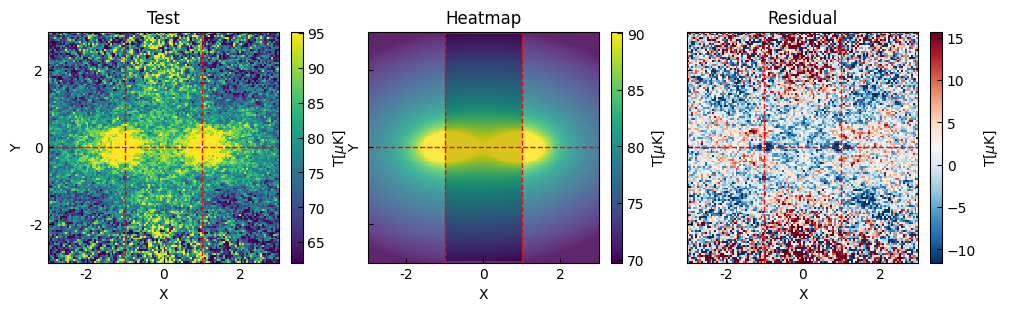

In [16]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [17]:
from mytools.plot import plot_hist

(-100.0, 100.0)

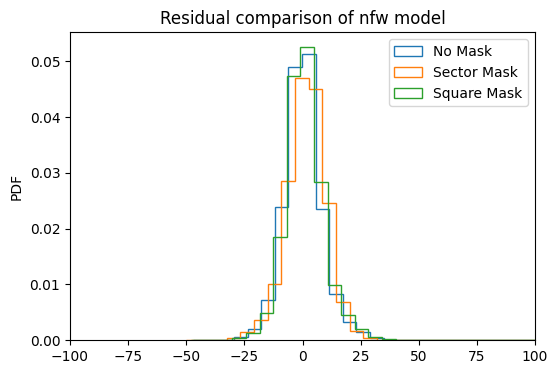

In [28]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [29]:
from mytools.plot import plot_line_diff, make_figure, plt, set_ticks

In [44]:
# stack_fit_res = data_list
# stack_fit_res = data_list_sector
stack_fit_res = data_list_square

In [45]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

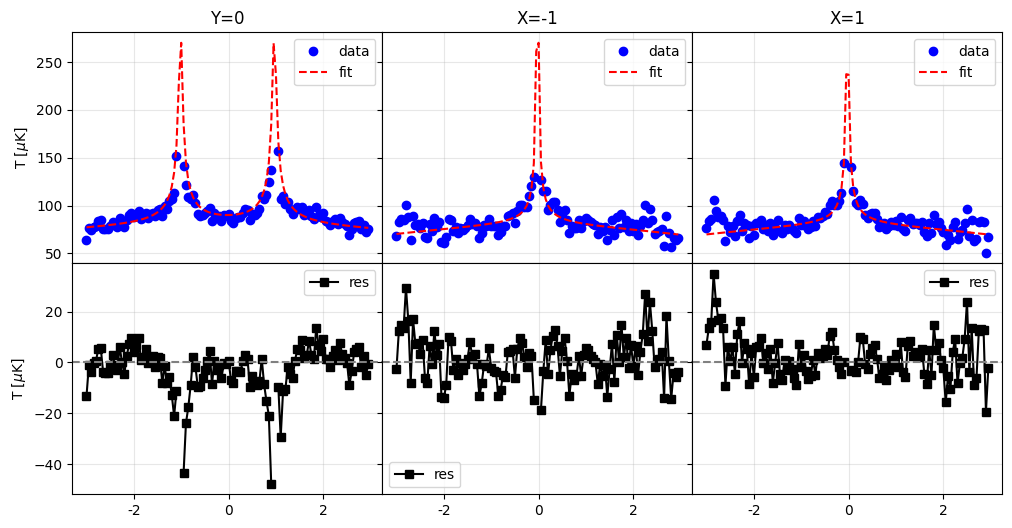

In [46]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)

# estimate signal level

In [47]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(-10.349030591221831), np.float64(0.0), np.float64(0.75), np.float64(6.385965538056211)]
Gauss fit covariance: 
[[ 0.16692438 -0.00601599 -0.12144589]
 [-0.00601599  0.00162836  0.01158504]
 [-0.12144589  0.01158504  0.14322919]]
0 points clipped during sigma clipping.
width: 0.75
width_pix: 15


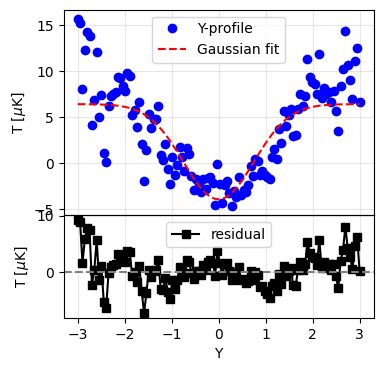

In [48]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.1, 0.75),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

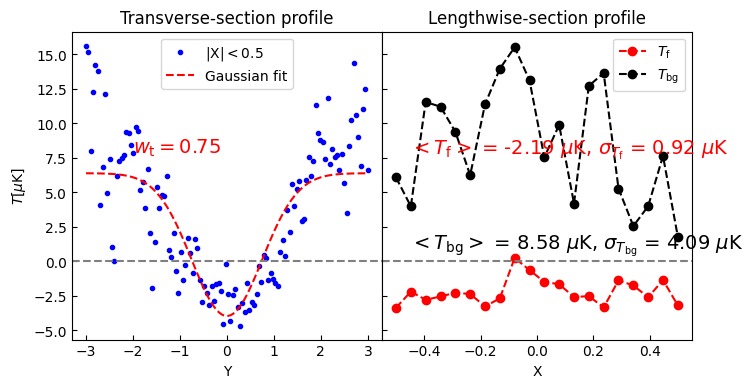

In [49]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

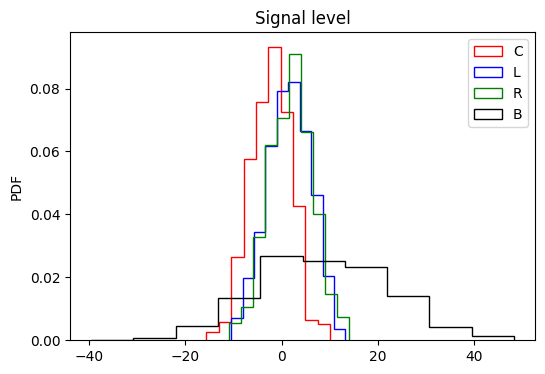

In [50]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')